# interrupt 승인 게이트

**이 노트북에서 할 일**

1. 노드 안의 멈춤 표시로 그래프를 멈추고, 멈춘 동안 무엇이 저장되는지 봅니다.
2. 사람의 답을 넣어 같은 실행을 이어 가고, 노드가 몇 번 시작하는지 셉니다.
3. 결제 기록을 먼저 적고 묻는 노드와, 묻고 나서 적는 노드에 같은 거절을 넣어 기록을 견줍니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
사람의 답은 우리가 셀에 적어 넣는 값(`"approve"`·`"reject"`)입니다.
실제 서비스라면 화면에서 사람이 고른 값을 같은 자리에 넣습니다.
매번 같은 값을 내는 우리 노드로, 기록이 몇 줄 남는지 출력으로 가릅니다.

결제는 실제 결제 서비스를 부르지 않고, Ch 23 06절처럼 기록 파일에 주문 키를 한 줄 적는 것으로 대신합니다.
노트북은 빈 임시 폴더를 만들어 그 폴더에서 실행합니다.
기록 파일은 모두 이 임시 폴더에 생기고, 실습 폴더에는 남지 않습니다.
읽어 오는 자료 파일은 없습니다.
걸린 시간은 재지 않았습니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
그래프는 langgraph 1.2.11, 체크포인터는 langgraph-checkpoint 4.2.0에 들어 있습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.
설치 셀에 걸리는 시간은 네트워크에 따라 달라집니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
멈춤 표시와 사람의 답을 보고, 묻는 자리와 적는 자리의 차례를 견주는 자리입니다.
6절은 묻기 전에 꼭 적어야 하는 기록을 한 번만 남기는 자리이고, 실습 시간에 실행합니다.
셀 하나만 다시 실행하면 같은 스레드와 같은 기록 파일에 이어 적어 값이 달라집니다.
처음 값으로 다시 보려면 1절 임시 폴더 셀부터 다시 실행합니다.

실습 폴더 `labs/part6/ch24-human-in-the-loop`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 상자 일곱이 한 줄로 이어진 흐름도입니다. 첫 초록 상자는 첫 invoke 주문 키 order-2401, 둘째 파란 상자는 노드 ask_only 시작 interrupt에서 멈춤입니다. 셋째 노란 상자는 멈춤 표시 하나와 질문 값, 체크포인트 둘입니다. 넷째 초록 상자는 사람의 답 approve, 다섯째 파란 상자는 Command resume=approve 같은 스레드로 invoke입니다. 여섯째 파란 상자는 노드 ask_only를 처음부터 다시 실행 interrupt가 답을 내놓음, 일곱째 노란 상자는 칸 answer approve 체크포인트 셋인 그림](attachment:01-1-멈추고-사람의-답으로-이어-가는-차례.png)

위에서 아래로 한 줄로 읽습니다.
초록 상자는 우리가 넣은 값과 사람의 답이고, 파란 상자는 우리가 적은 노드와 부른 줄입니다.
노란 상자는 노트북 2·3절에서 출력으로 확인한 값입니다.
둘째 상자와 여섯째 상자는 같은 노드이고, 노드는 두 번 시작했습니다.
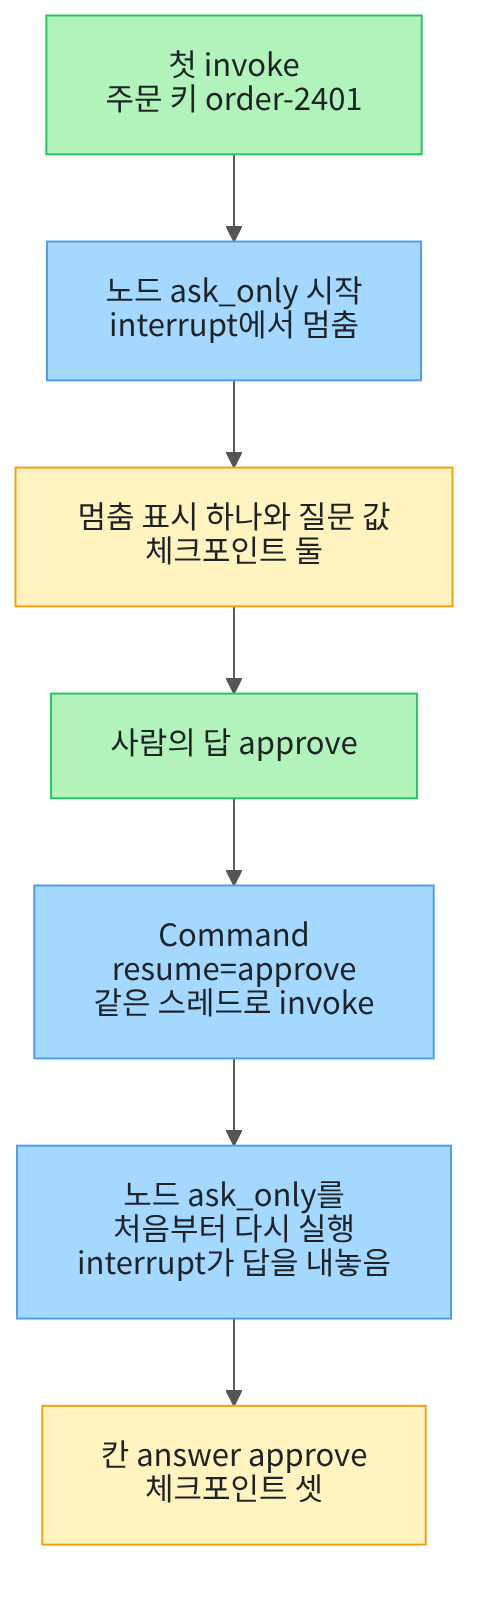

## 1. 준비

Ch 23에서는 체크포인터로 상태를 저장하고, 멈춘 실행을 저장된 자리부터 이어 갔습니다.
그때 실행이 멈춘 까닭은 실패나 강제 종료였습니다.
이 절에서는 그래프가 스스로 멈춰 사람의 확인을 기다리게 합니다.
절 제목의 「승인 게이트」는 Ch 17 02절의 승인 지점과 같은 뜻이라, 본문에서는 승인 지점이라고 씁니다.
Ch 18 01절의 게이트(중간 결과를 코드로 검사하는 자리)와는 다른 말입니다.

첫 셀은 패키지 둘을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langgraph-checkpoint==4.2.0"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langgraph-checkpoint:", version("langgraph-checkpoint"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langgraph-checkpoint: 4.2.0


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`과 `langgraph-checkpoint: 4.2.0`이 보입니다.
두 판 모두 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상태 형식과 그래프 이름은 Ch 13 01절, 체크포인터 `InMemorySaver`는 Ch 23 01절과 같습니다.
새로 쓰는 이름은 모듈 `langgraph.types`의 `interrupt`이고, 뜻은 2절에서 풉니다.
함께 가져오는 `Command`는 Ch 13 06절에서 갱신과 다음 노드 이름을 담았던 객체입니다.
마지막 가져오기 줄은 Ch 23에서 배운 함수 셋을 도구 파일 `approval_tools.py`에서 가져옵니다.

In [2]:
# 그래프 이름(Ch 13 01절)·체크포인터(Ch 23 01절)와, 멈춤 표시에 쓸 이름 둘을 가져옵니다
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
# interrupt는 노드를 멈추는 함수, Command는 멈춘 그래프에 사람의 답을 넘길 때 쓰는 객체입니다
from langgraph.types import Command, interrupt
# Ch 23 04·06절에서 배운 함수 셋을 도구 파일에서 가져옵니다
from approval_tools import append_key, append_key_once, read_record

print("langgraph.types에서 가져온 이름:", "Command, interrupt")
print("도구 파일에서 가져온 함수:", "append_key, append_key_once, read_record")

langgraph.types에서 가져온 이름: Command, interrupt
도구 파일에서 가져온 함수: append_key, append_key_once, read_record


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: append_key, append_key_once, read_record`가 보입니다.
세 함수는 Ch 23 04절과 06절 노트북에서 처음 적은 함수입니다.

앞에서 배운 함수는 `approval_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있어, 작업 위치를 옮기기 전에 가져왔습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

함수 `append_key`는 기록 파일 끝에 키 한 줄을 적고 글 `적음`을 내놓습니다.
함수 `append_key_once`는 같은 키가 이미 적혀 있으면 적지 않고 `건너뜀`을 내놓습니다.
함수 `read_record`는 기록 파일의 줄을 목록으로 읽습니다.
Ch 23 도구 파일은 SQLite 체크포인터를 가져와, 이 챕터에서는 쓰는 함수만 새 도구 파일에 옮겼습니다.

다음 셀은 Ch 23 01절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
이 절의 기록 파일은 모두 이 폴더에 생기고, 실습 폴더에는 남지 않습니다.
폴더 위치는 컴퓨터마다 달라 출력하지 않고, 폴더 이름의 앞머리만 확인합니다.

In [3]:
# 파일이 생기는지 볼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다(Ch 23 01절과 같은 모양)
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고, 그 폴더의 위치를 글로 내놓습니다
practice_folder = tempfile.mkdtemp(prefix="ch24-01-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
print("임시 폴더 이름에 ch24-01-이 들어 있는가:", "ch24-01-" in practice_folder)
print("현재 작업 폴더의 파일:", os.listdir())

임시 폴더 이름에 ch24-01-이 들어 있는가: True
현재 작업 폴더의 파일: []


**결과 읽기** — 출력 줄 `임시 폴더 이름에 ch24-01-이 들어 있는가: True`로, 이 절의 폴더를 만들었습니다.
출력 줄 `현재 작업 폴더의 파일: []`로, 빈 폴더에서 시작합니다.

## 2. 멈춤 표시로 멈추고 사람의 답으로 이어 가기

Ch 17 02절에서는 부작용이 생기는 단계 앞에서 사람이 확인하는 자리를 승인 지점이라고 불렀습니다.
Ch 17 03절의 사람 확인은 그 자리에 닿으면 반복을 멈추고 사람에게 넘겼고, 이어 가지는 않았습니다.
이 절은 그래프 안에 승인 지점을 두고, 사람의 답을 받아 같은 실행을 이어 갑니다.

먼저 상태 형식을 만듭니다.
칸 `order_key`는 주문 키, 칸 `record_name`은 결제 기록 파일 이름, 칸 `answer`는 사람의 답입니다.
세 칸 모두 규칙을 적지 않아, 새 값이 오면 덮어씁니다.

In [4]:
# 주문 키·결제 기록 파일 이름·사람의 답 칸을 둔 상태 형식을 만듭니다(Ch 13 01절 모양, 세 칸 모두 규칙 없음)
class ApprovalState(TypedDict):
    order_key: str
    record_name: str
    answer: str

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 절의 그래프 넷이 모두 이 상태 형식을 씁니다.

멈춤 표시(interrupt)는 노드가 그 자리에서 그래프를 멈추고, 사람에게 보일 값을 남기는 일입니다.
도미노 줄 가운데 한 자리를 비워 두면, 넘어지던 줄이 그 빈자리에서 멈추는 것과 같습니다.
이 절 코드에서는 노드 안에서 함수 `interrupt`를 부르는 줄입니다.

질문 값은 멈춤 표시와 함께 사람에게 보일 값입니다.
빈자리 옆에 세워 둔 안내판처럼, 무엇을 정해야 하는지 알려 줍니다.
이 절에서는 주문 키와 질문 글 `결제할까요?`를 담은 딕셔너리입니다.

다음 셀은 질문만 하고 파일은 쓰지 않는 노드입니다.
노드가 시작할 때와 답을 받은 뒤에 한 줄씩 출력하게 해, 노드가 몇 번 실행되는지 셀 출력으로 봅니다.

In [5]:
# 멈춤 표시로 사람에게 묻고, 받은 답을 칸 answer에 내는 노드입니다(파일은 쓰지 않습니다)
def ask_only(state):
    print("노드 ask_only 시작")
    # interrupt는 처음 부를 때 이 줄에서 그래프를 멈추고, 이어 갈 때는 사람의 답을 내놓습니다
    question = {"order_key": state["order_key"], "question": "결제할까요?"}
    answer = interrupt(question)
    print("받은 답:", answer)
    return {"answer": answer}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `interrupt`는 처음 부를 때 그 줄에서 노드를 멈춥니다.
그래서 첫 실행에서는 그 아래의 `받은 답:` 줄과 갱신을 내는 줄까지 가지 않습니다.

다음 셀은 이 노드 하나로 그래프를 만들고, Ch 23 01절처럼 체크포인터 `InMemorySaver`를 붙여 컴파일합니다.
멈춘 자리를 저장해 두어야 나중에 그 자리부터 이어 갈 수 있기 때문입니다.
공식 문서도 멈춤 표시를 쓰려면 체크포인터와 설정의 스레드 이름이 있어야 한다고 적습니다.

In [6]:
# 노드 하나를 START → ask_only → END로 잇고, 체크포인터를 붙여 컴파일합니다
ask_builder = StateGraph(ApprovalState)
ask_builder.add_node("ask_only", ask_only)
ask_builder.add_edge(START, "ask_only")
ask_builder.add_edge("ask_only", END)
# 멈춘 자리를 저장해 두어야 나중에 이어 갈 수 있어, 체크포인터를 붙입니다
ask_graph = ask_builder.compile(checkpointer=InMemorySaver())
ask_config = {"configurable": {"thread_id": "ask-only"}}
print("스레드 이름:", ask_config["configurable"]["thread_id"])
print("등록한 노드:", list(ask_builder.nodes))

스레드 이름: ask-only
등록한 노드: ['ask_only']


**결과 읽기** — 출력 줄 `등록한 노드: ['ask_only']`와 `스레드 이름: ask-only`가 보입니다.

다음 셀은 주문 키와 답 칸의 처음 값 `대기`를 넣어 실행합니다.
이 노드는 파일을 쓰지 않아, 칸 `record_name`은 넣지 않았습니다.
실행 전에 예상해 봅니다.
노드는 질문하는 줄에서 멈추고, 셀 출력에는 노드가 시작했다는 줄 하나만 보일 것입니다.

In [7]:
# 첫 실행: 노드가 멈춤 표시에서 멈추면, invoke는 그때까지의 상태를 내놓습니다
first_result = ask_graph.invoke({"order_key": "order-2401", "answer": "대기"}, ask_config)
print("결과의 키:", list(first_result))
print("칸 answer:", first_result["answer"])

노드 ask_only 시작
결과의 키: ['order_key', 'answer', '__interrupt__']
칸 answer: 대기


**결과 읽기** — 출력 첫 줄 `노드 ask_only 시작`은 노드 안의 `print`가 찍은 줄이고, `받은 답:` 줄은 없습니다.
출력 줄 `결과의 키: ['order_key', 'answer', '__interrupt__']`에 키 `__interrupt__`가 더해졌습니다.
출력 줄 `칸 answer: 대기`로, 칸 값은 아직 처음 값입니다.
노드가 끝나지 않았으므로 노드가 낼 갱신은 칸에 들어가지 않았습니다.

다음 셀은 키 `__interrupt__`에 든 것을 봅니다.
목록에는 멈춤 표시 하나마다 항목이 하나씩 들어 있습니다.
항목에는 아이디도 있는데, 실행마다 바뀌어 출력하지 않고 질문 값만 꺼냅니다.

In [8]:
# 키 __interrupt__의 목록에서 멈춤 표시 수와, 첫 멈춤 표시에 담긴 질문 값을 꺼냅니다
paused_marks = first_result["__interrupt__"]
print("멈춤 표시 수:", len(paused_marks))
first_mark = paused_marks[0]
print("멈춤 표시의 종류:", type(first_mark).__name__)
# 속성 value에는 interrupt에 넣은 질문 값이 그대로 들어 있습니다(아이디는 실행마다 달라 출력하지 않음)
print("질문 값:", first_mark.value)

멈춤 표시 수: 1
멈춤 표시의 종류: Interrupt
질문 값: {'order_key': 'order-2401', 'question': '결제할까요?'}


**결과 읽기** — 출력 줄 `멈춤 표시 수: 1`과 `멈춤 표시의 종류: Interrupt`가 보입니다.
출력 줄 `질문 값: {'order_key': 'order-2401', 'question': '결제할까요?'}`는 노드가 함수 `interrupt`에 넣은 딕셔너리 그대로입니다.
실제 서비스라면 이 질문 값을 화면에 띄우고, 사람이 고른 답을 받습니다.

## 3. 멈춘 동안 저장된 것

그래프가 멈춘 동안 체크포인터에 무엇이 남았는지, Ch 23 01절의 `get_state`로 읽습니다.
다음 셀은 다음에 실행할 노드와 저장된 칸 값을 봅니다.

In [9]:
# 멈춘 스레드의 마지막 체크포인트에서 다음에 실행할 노드와 저장된 칸 값을 읽습니다
paused_state = ask_graph.get_state(ask_config)
print("다음에 실행할 노드:", paused_state.next)
print("저장된 칸 값:", paused_state.values)

다음에 실행할 노드: ('ask_only',)
저장된 칸 값: {'order_key': 'order-2401', 'answer': '대기'}


**결과 읽기** — 출력 줄 `다음에 실행할 노드: ('ask_only',)`와 `저장된 칸 값: {'order_key': 'order-2401', 'answer': '대기'}`입니다.
노드 `ask_only`는 끝나지 않아, 다음에 실행할 노드로 남았습니다.
Ch 23 05절에서 실패로 멈춘 노드가 다음 노드로 남았던 것과 같은 자리입니다.

다음 셀은 속성 `tasks`로 멈춘 작업을 봅니다.
Ch 23 05절에서 실패한 작업의 오류를 읽었던 속성입니다.
이번에는 작업에 딸린 멈춤 표시의 질문 값을 읽고, 체크포인트 수도 셉니다.

In [10]:
# 멈춘 작업(task)에 딸린 질문 값과, 지금까지 쌓인 체크포인트 수를 봅니다
paused_task = paused_state.tasks[0]
print("멈춘 작업의 노드:", paused_task.name)
# 속성 interrupts는 이 작업에 딸린 멈춤 표시의 목록입니다
print("작업에 딸린 질문 값:", paused_task.interrupts[0].value)
paused_history = list(ask_graph.get_state_history(ask_config))
print("체크포인트 수:", len(paused_history))

멈춘 작업의 노드: ask_only
작업에 딸린 질문 값: {'order_key': 'order-2401', 'question': '결제할까요?'}
체크포인트 수: 2


**결과 읽기** — 출력 줄 `멈춘 작업의 노드: ask_only`와 `체크포인트 수: 2`가 보입니다.
출력 줄 `작업에 딸린 질문 값: {'order_key': 'order-2401', 'question': '결제할까요?'}`로, 질문 값도 저장되었습니다.
그래서 그래프는 사람이 답할 때까지 기다릴 수 있습니다.
체크포인트 둘은 입력을 받은 때와 입력을 칸에 넣은 뒤이고, 노드를 마친 뒤의 것은 아직 없습니다.

사람의 답으로 이어 가기는 멈춘 스레드에 사람의 답을 넘겨, 멈춘 노드부터 실행을 이어 가는 일입니다.
도미노 줄의 빈자리에 사람이 도미노 하나를 놓으면, 뒤쪽 줄이 다시 넘어가기 시작하는 것과 같습니다.
이 절 코드에서는 `Command(resume=답)`을 `invoke`에 넣는 줄입니다.
자리 `resume`에 넣은 값이, 노드 안 함수 `interrupt`가 내놓는 값이 됩니다.
비유와 달리 실제 그래프는 멈춘 줄이 아니라 노드의 첫 줄부터 다시 실행하고, 다음 셀에서 그 모습을 봅니다.

Ch 23 03절의 스레드 재개는 객체를 새로 만든 뒤 같은 스레드로 대화를 이어 가는 일이었습니다.
Ch 23 04·06절 스크립트의 단계 `resume`은 강제 종료 뒤 새 프로세스로 다시 실행하는 단계였습니다.
이름에 같은 영어 낱말이 들어 있어도, 사람의 답을 넣어 이어 가는 이 절의 장면과는 다릅니다.

다음 셀은 사람의 답 `approve`로 이어 갑니다.
실행 전에 예상해 봅니다.
노드가 처음부터 다시 실행되어 시작 줄이 한 번 더 찍히고, 이번에는 답을 받을 것입니다.

In [11]:
# 사람의 답 "approve"를 Command의 자리 resume에 담아, 같은 스레드로 이어 갑니다
resume_result = ask_graph.invoke(Command(resume="approve"), ask_config)
print("이어 간 뒤 결과:", resume_result)

노드 ask_only 시작
받은 답: approve
이어 간 뒤 결과: {'order_key': 'order-2401', 'answer': 'approve'}


**결과 읽기** — 출력 첫 줄 `노드 ask_only 시작`이 이 셀에서 한 번 더 찍혔습니다.
노드는 멈춘 줄이 아니라 첫 줄부터 다시 실행되었습니다.
출력 줄 `받은 답: approve`로, 함수 `interrupt`가 이번에는 멈추지 않고 사람의 답을 내놓았습니다.
출력 줄 `이어 간 뒤 결과: {'order_key': 'order-2401', 'answer': 'approve'}`에는 키 `__interrupt__`가 없습니다.

공식 문서도 이어 갈 때 멈춘 줄이 아니라 노드 전체를 처음부터 다시 시작한다고 적습니다.
다음 셀은 이어 간 뒤의 체크포인트를 봅니다.

In [12]:
# 이어 간 뒤 다음에 실행할 노드와 체크포인트 수를 봅니다
done_state = ask_graph.get_state(ask_config)
print("다음에 실행할 노드:", done_state.next)
done_history = list(ask_graph.get_state_history(ask_config))
print("체크포인트 수:", len(done_history))
# 노드 하나짜리 그래프를 한 번 끝까지 실행한 수라, 실행마다 같아야 합니다
assert len(done_history) == 3, "이어 간 뒤 체크포인트는 셋이어야 합니다"

다음에 실행할 노드: ()
체크포인트 수: 3


**결과 읽기** — 출력 줄 `다음에 실행할 노드: ()`와 `체크포인트 수: 3`입니다.
멈춘 동안의 둘에, 노드를 마친 뒤의 하나가 더해졌습니다.
Ch 23 01절에서 노드 하나짜리 그래프를 한 번 실행했을 때 쌓인 수와 같습니다.
노드는 두 번 시작했지만 끝난 것은 한 번이라, 체크포인트도 하나만 늘었습니다.

## 4. 적고 나서 묻는 노드 (Before)

이제 승인 지점 앞뒤에 부작용을 둡니다.
부작용은 Ch 23 06절처럼 결제 기록 파일에 주문 키를 한 줄 적는 일입니다.
먼저 결제 기록을 적은 뒤에 묻는 노드를 만듭니다.
3절에서 본 대로, 노드는 이어 갈 때 처음부터 다시 실행된다는 점을 떠올려 봅니다.

In [13]:
# Before 노드: 결제 기록 파일에 주문 키를 먼저 적고, 그다음 멈춤 표시로 묻습니다
def charge_then_ask(state):
    print("노드 charge_then_ask 시작")
    note = append_key(state["record_name"], state["order_key"])
    print("결제 기록:", note)
    question = {"order_key": state["order_key"], "question": "결제할까요?"}
    answer = interrupt(question)
    print("받은 답:", answer)
    return {"answer": answer}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `append_key`는 부를 때마다 기록 파일 끝에 키 한 줄을 적습니다.
이 노드에서는 그 줄이 멈춤 표시보다 앞에 있습니다.

다음 셀은 2절과 같은 모양으로, 이 노드 하나짜리 그래프를 만듭니다.

In [14]:
# 노드 하나를 START → charge_then_ask → END로 잇고, 체크포인터를 붙여 컴파일합니다
before_builder = StateGraph(ApprovalState)
before_builder.add_node("charge_then_ask", charge_then_ask)
before_builder.add_edge(START, "charge_then_ask")
before_builder.add_edge("charge_then_ask", END)
# 멈춘 자리를 저장해 두어야 나중에 이어 갈 수 있어, 체크포인터를 붙입니다
before_graph = before_builder.compile(checkpointer=InMemorySaver())
print("등록한 노드:", list(before_builder.nodes))

등록한 노드: ['charge_then_ask']


**결과 읽기** — 출력 줄 `등록한 노드: ['charge_then_ask']`입니다.

다음 셀은 첫 실행을 합니다.
기록 파일 이름은 `before.record`, 스레드 이름은 `before`입니다.
실행 전에 예상해 봅니다.
노드는 묻기 전에 기록을 적으니, 멈춘 지금 파일에는 키가 한 줄 있을 것입니다.

In [15]:
# 첫 실행: 기록 파일 이름 before.record를 넣고, 멈춘 뒤 그 파일에 적힌 키를 읽습니다
before_config = {"configurable": {"thread_id": "before"}}
before_input = {"order_key": "order-2401", "record_name": "before.record", "answer": "대기"}
before_paused = before_graph.invoke(before_input, before_config)
print("멈춤 표시 수:", len(before_paused["__interrupt__"]))
print("멈춘 뒤 기록 파일의 키:", read_record("before.record"))

노드 charge_then_ask 시작
결제 기록: 적음
멈춤 표시 수: 1
멈춘 뒤 기록 파일의 키: ['order-2401']


**결과 읽기** — 출력 줄 `노드 charge_then_ask 시작`과 `결제 기록: 적음` 다음에 그래프가 멈췄습니다.
출력 줄 `멈춤 표시 수: 1`로, 멈춤 표시가 하나 남았습니다.
출력 줄 `멈춘 뒤 기록 파일의 키: ['order-2401']`입니다.
사람이 아직 답하지 않았는데, 결제 기록은 이미 한 줄 적혔습니다.

다음 셀은 사람의 답 `reject`로 이어 갑니다.
거절이니 결제 기록은 남지 않아야 합니다.
실행 전에 예상해 봅니다.
노드가 처음부터 다시 실행되니, 기록을 한 번 더 적을 것입니다.

In [16]:
# 사람의 답 "reject"로 이어 가고, 칸 answer와 결제 기록 파일의 키를 봅니다
before_result = before_graph.invoke(Command(resume="reject"), before_config)
print("칸 answer:", before_result["answer"])
before_keys = read_record("before.record")
print("기록 파일의 키:", before_keys)
before_count = before_keys.count("order-2401")
print("같은 키가 적힌 줄 수:", before_count)
# 우리 노드가 정하는 값이라 실행마다 같아야 합니다
assert before_count == 2, "적고 나서 묻는 노드는 거절해도 같은 키를 두 줄 남깁니다"

노드 charge_then_ask 시작
결제 기록: 적음
받은 답: reject
칸 answer: reject
기록 파일의 키: ['order-2401', 'order-2401']
같은 키가 적힌 줄 수: 2


**결과 읽기** — 출력 줄 `노드 charge_then_ask 시작`과 `결제 기록: 적음`이 이 셀에서 한 번 더 찍혔습니다.
출력 줄 `받은 답: reject`와 `칸 answer: reject`로, 사람은 거절했습니다.
그런데 출력 줄 `기록 파일의 키: ['order-2401', 'order-2401']`과 `같은 키가 적힌 줄 수: 2`입니다.
거절했는데도 결제 기록이 두 줄 남았습니다.
이것이 이 절의 Before 결함입니다.

결함은 둘입니다.
하나는 사람이 답하기 전에 이미 적었다는 것입니다.
다른 하나는 이어 갈 때 노드가 처음부터 다시 실행되어, 한 번 더 적었다는 것입니다.
승인 지점을 두었어도, 부작용이 그 앞에 있으면 거절이 쓰기를 막지 못합니다.

## 5. 묻고 나서 적는 노드 (After)

이제 결함을 고칩니다.
바꾸는 것은 노드 안 줄의 차례 하나입니다.
먼저 묻고, 받은 답이 `approve`일 때만 결제 기록을 적습니다.

In [17]:
# After 노드: 먼저 멈춤 표시로 묻고, 답이 approve일 때만 결제 기록을 적습니다
def ask_then_charge(state):
    print("노드 ask_then_charge 시작")
    question = {"order_key": state["order_key"], "question": "결제할까요?"}
    answer = interrupt(question)
    print("받은 답:", answer)
    if answer == "approve":
        note = append_key(state["record_name"], state["order_key"])
        print("결제 기록:", note)
    return {"answer": answer}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
멈춤 표시 앞에는 파일을 건드리는 줄이 없습니다.
그래서 이어 갈 때 노드가 처음부터 다시 실행되어도, 멈추기 전에 적는 일은 없습니다.
답이 `approve`가 아니면 쓰는 줄을 건너뛰고, 답만 칸에 냅니다.

다음 셀은 4절과 같은 모양으로 그래프를 만듭니다.

In [18]:
# 노드 하나를 START → ask_then_charge → END로 잇고, 체크포인터를 붙여 컴파일합니다
after_builder = StateGraph(ApprovalState)
after_builder.add_node("ask_then_charge", ask_then_charge)
after_builder.add_edge(START, "ask_then_charge")
after_builder.add_edge("ask_then_charge", END)
# 멈춘 자리를 저장해 두어야 나중에 이어 갈 수 있어, 체크포인터를 붙입니다
after_graph = after_builder.compile(checkpointer=InMemorySaver())
print("등록한 노드:", list(after_builder.nodes))

등록한 노드: ['ask_then_charge']


**결과 읽기** — 출력 줄 `등록한 노드: ['ask_then_charge']`입니다.

다음 셀은 4절과 같은 주문 키로 첫 실행을 합니다.
기록 파일 이름은 `after-reject.record`, 스레드 이름은 `after-reject`입니다.
파일이 있는지는 Ch 23 04절에서 쓴 함수 `os.path.exists`로 봅니다.
실행 전에 예상해 봅니다.
묻기 전에는 적지 않으니, 멈춘 지금 기록 파일은 없을 것입니다.

In [19]:
# 첫 실행: 기록 파일 이름 after-reject.record를 넣고, 멈춘 뒤 그 파일이 있는지 봅니다
reject_config = {"configurable": {"thread_id": "after-reject"}}
reject_input = {"order_key": "order-2401", "record_name": "after-reject.record", "answer": "대기"}
reject_paused = after_graph.invoke(reject_input, reject_config)
print("멈춤 표시 수:", len(reject_paused["__interrupt__"]))
print("기록 파일이 있는가:", os.path.exists("after-reject.record"))

노드 ask_then_charge 시작
멈춤 표시 수: 1
기록 파일이 있는가: False


**결과 읽기** — 출력 줄 `노드 ask_then_charge 시작` 다음에 그래프가 멈췄고, 출력 줄 `멈춤 표시 수: 1`이 보입니다.
출력 줄 `기록 파일이 있는가: False`로, 멈춘 지금 기록 파일이 없습니다.

다음 셀은 4절과 같은 답 `reject`로 이어 갑니다.
실행 전에 예상해 봅니다.
노드는 처음부터 다시 실행되지만, 답이 거절이라 파일은 여전히 없을 것입니다.

In [20]:
# 4절과 같은 답 "reject"로 이어 가고, 칸 answer와 기록 파일이 있는지 봅니다
reject_result = after_graph.invoke(Command(resume="reject"), reject_config)
print("칸 answer:", reject_result["answer"])
reject_exists = os.path.exists("after-reject.record")
print("기록 파일이 있는가:", reject_exists)
# 거절이면 쓰는 줄에 닿지 않으므로 실행마다 같아야 합니다
assert not reject_exists, "묻고 나서 적는 노드는 거절이면 기록 파일을 만들지 않습니다"

노드 ask_then_charge 시작
받은 답: reject
칸 answer: reject
기록 파일이 있는가: False


**결과 읽기** — 출력 줄 `노드 ask_then_charge 시작`이 이 셀에서 한 번 더 찍혔고, `받은 답: reject`가 뒤따릅니다.
출력 줄 `칸 answer: reject`와 `기록 파일이 있는가: False`입니다.
노드는 4절처럼 두 번 시작했지만, 결제 기록은 한 줄도 남지 않았습니다.
사람의 거절이 쓰기를 막았습니다.

값 바꿔 보기: 사람의 답 하나만 `approve`로 바꿉니다.
스레드와 기록 파일은 새 이름 `after-approve`를 씁니다.
다음 셀은 첫 실행입니다.
실행 전에 예상해 봅니다.
여기까지는 거절 때와 같이, 멈춘 지금 기록 파일이 없을 것입니다.

In [21]:
# 값 바꿔 보기: 새 스레드 after-approve로 첫 실행을 하고, 멈춘 뒤 기록 파일이 있는지 봅니다
approve_config = {"configurable": {"thread_id": "after-approve"}}
approve_input = {"order_key": "order-2401", "record_name": "after-approve.record", "answer": "대기"}
approve_paused = after_graph.invoke(approve_input, approve_config)
print("멈춤 표시 수:", len(approve_paused["__interrupt__"]))
print("기록 파일이 있는가:", os.path.exists("after-approve.record"))

노드 ask_then_charge 시작
멈춤 표시 수: 1
기록 파일이 있는가: False


**결과 읽기** — 출력 줄 `멈춤 표시 수: 1`과 `기록 파일이 있는가: False`는 거절 때의 첫 실행과 같습니다.

다음 셀은 사람의 답 `approve`로 이어 갑니다.
실행 전에 예상해 봅니다.
이어 갈 때 쓰는 줄에 한 번 닿으니, 결제 기록은 한 줄일 것입니다.

In [22]:
# 사람의 답 하나만 "approve"로 바꿔 이어 가고, 칸 answer와 결제 기록 파일의 키를 봅니다
approve_result = after_graph.invoke(Command(resume="approve"), approve_config)
print("칸 answer:", approve_result["answer"])
approve_keys = read_record("after-approve.record")
print("기록 파일의 키:", approve_keys)
approve_count = approve_keys.count("order-2401")
print("같은 키가 적힌 줄 수:", approve_count)
# 쓰는 줄은 멈춤 표시 뒤에 있어, 노드가 두 번 시작해도 한 번만 적습니다
assert approve_count == 1, "묻고 나서 적는 노드는 승인이면 키를 한 줄만 남깁니다"

노드 ask_then_charge 시작
받은 답: approve
결제 기록: 적음
칸 answer: approve
기록 파일의 키: ['order-2401']
같은 키가 적힌 줄 수: 1


**결과 읽기** — 출력 줄 `받은 답: approve` 다음에 `결제 기록: 적음`이 찍혔습니다.
출력 줄 `기록 파일의 키: ['order-2401']`과 `같은 키가 적힌 줄 수: 1`입니다.
승인하자 결제 기록이 한 줄 남았습니다.
쓰는 줄이 멈춤 표시 뒤에 있어, 노드가 두 번 시작해도 한 번만 적었습니다.

## 6. 묻기 전에 꼭 적어야 한다면

되돌리기 어려운 일은 5절처럼 묻고 나서 합니다.
그런데 사람이 답하기 전에 남겨야 하는 기록도 있습니다.
예를 들어 요청을 받았다는 접수 기록은 묻기 전에 적어 둘 수 있습니다.
공식 문서는 멈춤 표시 앞의 부작용을 되도록 멱등하게 만들라고 적습니다.
Ch 23 06절에서 멱등성은 몇 번 실행해도 결과가 한 번 실행한 것과 같은 성질이었습니다.

다음 셀은 4절 노드에서 쓰는 함수 하나만 `append_key_once`로 바꾼 노드입니다.
적는 곳은 결제 기록이 아니라 접수 기록 파일입니다.

In [23]:
# 접수 기록을 멱등하게 먼저 적고(같은 키가 있으면 건너뜀), 그다음 멈춤 표시로 묻는 노드입니다
def receive_then_ask(state):
    print("노드 receive_then_ask 시작")
    note = append_key_once(state["record_name"], state["order_key"])
    print("접수 기록:", note)
    question = {"order_key": state["order_key"], "question": "결제할까요?"}
    answer = interrupt(question)
    print("받은 답:", answer)
    return {"answer": answer}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `append_key_once`는 Ch 23 06절에서 배운 함수이고, 주문 키가 멱등 키입니다.

다음 셀은 이 노드 하나짜리 그래프를 만듭니다.

In [24]:
# 노드 하나를 START → receive_then_ask → END로 잇고, 체크포인터를 붙여 컴파일합니다
receipt_builder = StateGraph(ApprovalState)
receipt_builder.add_node("receive_then_ask", receive_then_ask)
receipt_builder.add_edge(START, "receive_then_ask")
receipt_builder.add_edge("receive_then_ask", END)
# 멈춘 자리를 저장해 두어야 나중에 이어 갈 수 있어, 체크포인터를 붙입니다
receipt_graph = receipt_builder.compile(checkpointer=InMemorySaver())
print("등록한 노드:", list(receipt_builder.nodes))

등록한 노드: ['receive_then_ask']


**결과 읽기** — 출력 줄 `등록한 노드: ['receive_then_ask']`입니다.

다음 셀은 기록 파일 이름 `receipt.record`로 첫 실행을 하고, 4절과 같은 답 `reject`로 이어 갑니다.
실행 전에 예상해 봅니다.
노드는 두 번 시작하지만, 둘째에는 이미 적힌 키를 찾아 건너뛸 것입니다.

In [25]:
# 기록 파일 이름 receipt.record로 첫 실행을 한 뒤, 4절과 같은 답 "reject"로 이어 갑니다
receipt_config = {"configurable": {"thread_id": "receipt"}}
receipt_input = {"order_key": "order-2401", "record_name": "receipt.record", "answer": "대기"}
receipt_graph.invoke(receipt_input, receipt_config)
print("멈춘 뒤 접수 기록의 키:", read_record("receipt.record"))
receipt_result = receipt_graph.invoke(Command(resume="reject"), receipt_config)
print("칸 answer:", receipt_result["answer"])
print("이어 간 뒤 접수 기록의 키:", read_record("receipt.record"))

노드 receive_then_ask 시작
접수 기록: 적음
멈춘 뒤 접수 기록의 키: ['order-2401']
노드 receive_then_ask 시작
접수 기록: 건너뜀
받은 답: reject
칸 answer: reject
이어 간 뒤 접수 기록의 키: ['order-2401']


**결과 읽기** — 첫 실행에서 `접수 기록: 적음`이, 이어 갈 때 `접수 기록: 건너뜀`이 찍혔습니다.
출력 줄 `멈춘 뒤 접수 기록의 키: ['order-2401']`과 `이어 간 뒤 접수 기록의 키: ['order-2401']`이 같습니다.
노드는 두 번 시작했지만, 접수 기록은 한 줄만 남았습니다.
출력 줄 `칸 answer: reject`처럼 거절했어도, 이 한 줄은 남습니다.
그래서 멱등하게 적는 방법은 접수 기록처럼 거절돼도 남아도 되는 쓰기에만 씁니다.

다음 셀은 4~6절의 네 장면을 한 목록에 모읍니다.
사람의 답은 각 장면의 결과에서 칸 `answer`를 꺼내 씁니다.

In [26]:
# 4~6절의 네 장면을 노드 이름·사람의 답·기록 파일 이름 한 줄씩으로 모읍니다
scenes = []
scenes.append(["charge_then_ask", before_result["answer"], "before.record"])
scenes.append(["ask_then_charge", reject_result["answer"], "after-reject.record"])
scenes.append(["ask_then_charge", approve_result["answer"], "after-approve.record"])
scenes.append(["receive_then_ask", receipt_result["answer"], "receipt.record"])
print("모은 장면 수:", len(scenes))

모은 장면 수: 4


**결과 읽기** — 출력 줄 `모은 장면 수: 4`입니다.

다음 셀은 장면마다 기록 파일에 같은 주문 키가 적힌 줄 수를 세어, 한 줄씩 출력합니다.
기록 파일이 없으면 줄 수를 0으로 둡니다.

In [27]:
# 장면마다 기록 파일에 같은 주문 키가 적힌 줄 수를 세어, 라벨 줄 아래에 한 줄씩 출력합니다
print("노드 | 사람의 답 | 기록 파일 | 같은 키가 적힌 줄 수")
for scene in scenes:
    # 기록 파일이 없으면 적힌 줄이 없으므로 0으로 둡니다
    key_count = 0
    if os.path.exists(scene[2]):
        scene_keys = read_record(scene[2])
        key_count = scene_keys.count("order-2401")
    print(scene[0], "|", scene[1], "|", scene[2], "|", key_count)

노드 | 사람의 답 | 기록 파일 | 같은 키가 적힌 줄 수
charge_then_ask | reject | before.record | 2
ask_then_charge | reject | after-reject.record | 0
ask_then_charge | approve | after-approve.record | 1
receive_then_ask | reject | receipt.record | 1


**결과 읽기** — 라벨 줄 아래 첫 줄은 `charge_then_ask | reject | before.record | 2`입니다.
그 아래 세 줄은 `ask_then_charge | reject | after-reject.record | 0`과 `ask_then_charge | approve | after-approve.record | 1`, `receive_then_ask | reject | receipt.record | 1`입니다.
같은 거절이라도 적는 줄이 멈춤 표시 앞에 있으면 기록이 남았습니다.
멈춤 표시 뒤에서 적으면 승인일 때만 한 줄이었습니다.

다음 셀은 작업 폴더에 남은 파일을 봅니다.

In [28]:
# 작업 폴더에 남은 파일을 봅니다(모두 이 절의 임시 폴더 안에 있습니다)
file_names = sorted(os.listdir())
print("작업 폴더의 파일:", file_names)
print("파일 수:", len(file_names))

작업 폴더의 파일: ['after-approve.record', 'before.record', 'receipt.record']
파일 수: 3


**결과 읽기** — 출력 줄 `작업 폴더의 파일: ['after-approve.record', 'before.record', 'receipt.record']`와 `파일 수: 3`입니다.
거절한 `after-reject.record`는 만들어지지 않았습니다.
이 파일들은 모두 임시 폴더에 있어, 실습 폴더에는 남지 않습니다.

## 정리

1. 노드 안에서 함수 `interrupt`를 부르자 그래프가 멈추고, 결과의 키 `__interrupt__`에 질문 값이 남았습니다.
2. 사람의 답을 `Command(resume=…)`에 담아 이어 가자, 노드가 처음부터 다시 실행되었습니다.
3. 적고 나서 묻는 노드는 거절에도 결제 기록을 두 줄 남겼고, 묻고 나서 적는 노드는 거절이면 0줄이었습니다.

02절에서는 사람의 답을 검사해, 허용하지 않는 값이면 다시 묻는 방법을 봅니다.